*Inspirado en: [moloxe.com/blog/transformada-discreta-de-fourier-dft-en-javascript/#fft](https://moloxe.com/blog/transformada-discreta-de-fourier-dft-en-javascript/#fft)*

# 🎨 Experimento 2026-10 (Parte 3): Carga Progresiva Secuencial a Color (Espacio YCbCr y Entrelazado Perceptual 1D)
**Proyecto:** `<mx-img />` - Carga Progresiva de Imágenes por Secuencia de Frecuencias

## Contexto y Evolución del Experimento
En el experimento anterior ([`2026-10-new-format-02.ipynb`](2026-10-new-format-02.ipynb)), logramos serializar el espectro 2D de Fourier en un **único flujo 1D continuo** ordenado por prioridad radial implícita para una imagen en escala de grises. Sin embargo, extender este flujo a imágenes en color ($	ext{RGB}$) plantea dos retos críticos de arquitectura:
1. **Evitar la aparición tardía del color:** Si transmitimos primero todo el canal $R$, luego el $G$ y finalmente el $B$ (o primero todo $Y$ y al final la crominancia), la imagen se visualizaría monocromática o con colores falsos durante dos tercios de la descarga.
2. **Evitar triplicar innecesariamente el peso del stream:** Codificar los 3 canales al $100\%$ de frecuencias triplica el ancho de banda ($3 	imes H 	imes W$), desperdiciando datos en altas frecuencias cromáticas que el sistema visual humano no es capaz de percibir.

En esta etapa implementamos el **pipeline espectral multicanal secuencial** con cuatro pilares:
1. **Conversión de $	ext{RGB}$ a $	ext{YCbCr}$ previa a la FFT:** Desacoplamos la **Luminancia ($Y$)** —que concentra los bordes y el detalle estructural fino— de la **Crominancia ($Cb, Cr$)** —donde la energía relevante reside casi por completo en las frecuencias bajas—.
2. **Reutilización del mapa de ordenamiento radial:** El vector determinista `orden_radial` depende exclusivamente de $(H, W)$. Se calcula **una sola vez** y se aplica por igual a las matrices espectrales centradas de los 3 canales.
3. **Entrelazado frecuencial con priorización perceptual (Interleaving):**
   - **Modo Simple ($1:1:1$):** Para cada índice radial $k$, empaquetamos la tupla contigua $[Y_k, Cb_k, Cr_k]$.
   - **Modo con Priorización Perceptual (Recomendado):** En las frecuencias bajas (el primer $15\%$ del radio espectral), enviamos la tripleta completa $[Y_k, Cb_k, Cr_k]$. Superado dicho umbral, dejamos de transmitir $Cb$ y $Cr$ (permanecen en cero complejo en el receptor) y enviamos **únicamente coeficientes de luminancia $Y_k$**, destinando todo el ancho de banda restante a perfilar bordes y texturas.
4. **Decodificación progresiva multicanal en el receptor:** A partir de cualquier prefijo `secuencia[:K]`, el receptor reparte los coeficientes en 3 matrices complejas de ceros $(H, W)$ usando el mismo `orden_radial`, ejecuta `ifftshift` + `2D-IFFT` por canal, apila con `np.dstack`, convierte de $	ext{YCbCr}$ a $	ext{RGB}$ y acota al rango `0–255` (`uint8`).

In [10]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from functools import lru_cache

# Configuración visual general
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'

# Ubicación de la imagen de prueba (búsqueda robusta compatible con cualquier entorno o CWD)
candidate_paths = [
    '../images/image.jpeg',
    'images/image.jpeg',
    'experiments/images/image.jpeg',
    '/Users/francomolochegarcia/dev/mx-img/experiments/images/image.jpeg'
]
img_path = next((p for p in candidate_paths if os.path.exists(p)), None)
assert img_path is not None, f"No se encontró la imagen en ninguna ruta: {candidate_paths}"
print(f"✅ Entorno preparado y archivo verificado: {img_path}")

✅ Entorno preparado y archivo verificado: ../images/image.jpeg


## 🎨 Paso 1: Conversión de $	ext{RGB}$ a $	ext{YCbCr}$ antes de la FFT

En lugar de transformar directamente los canales $R, G, B$ (altamente correlacionados entre sí), proyectamos la imagen al espacio **$	ext{YCbCr}$** (estándar ITU-R BT.601 de rango completo $[0, 255]$ en coma flotante de doble precisión para evitar pérdidas por redondeo intermedio):

$$\begin{aligned}
Y  &= 0.299\,R + 0.587\,G + 0.114\,B \\
Cb &= 128 - 0.168736\,R - 0.331264\,G + 0.5\,B \\
Cr &= 128 + 0.5\,R - 0.418688\,G - 0.081312\,B
\end{aligned}$$

Y su transformación inversa exacta $	ext{YCbCr} \to 	ext{RGB}$ en el decodificador:

$$\begin{aligned}
R &= Y + 1.402\,(Cr - 128) \\
G &= Y - 0.344136\,(Cb - 128) - 0.714136\,(Cr - 128) \\
B &= Y + 1.772\,(Cb - 128)
\end{aligned}$$

* **$Y$ (Luminancia):** Equivalente a la imagen en escala de grises; preserva la totalidad de los contornos, micro-contrastes y frecuencias espaciales altas.
* **$Cb, Cr$ (Crominancia Azul y Roja):** Contienen únicamente transiciones suaves de color, cuya energía espectral cae drásticamente fuera del núcleo central de bajas frecuencias.

🖼️ Imagen RGB cargada: ../images/image.jpeg
📏 Dimensiones: 800 × 780 × 3 (Ancho × Alto × Canales) | Píxeles por canal: 624,000


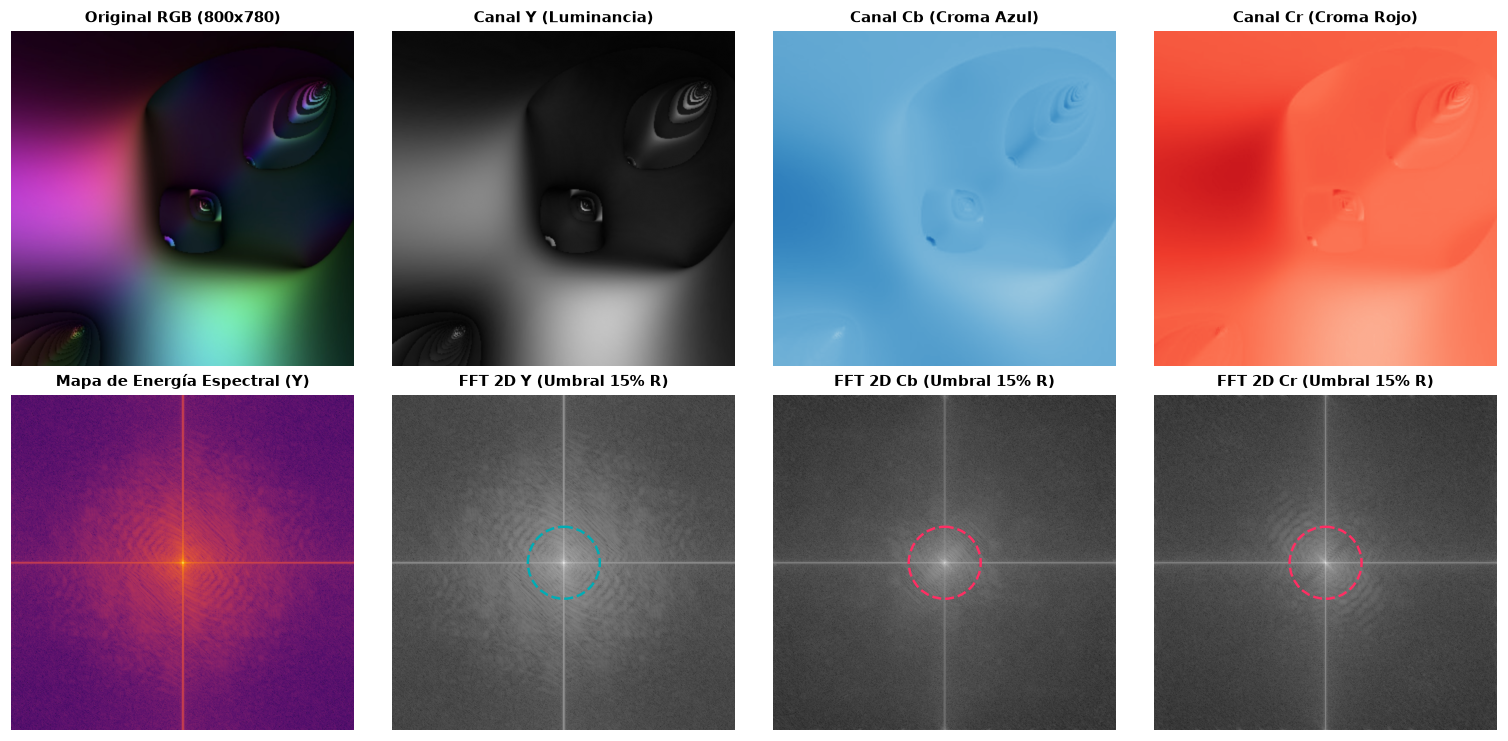

In [11]:
def rgb_to_ycbcr(img_rgb: np.ndarray) -> np.ndarray:
    """
    Convierte una imagen RGB [0, 255] al espacio YCbCr en punto flotante (float64)
    siguiendo la matriz estándar ITU-R BT.601 (rango completo).
    """
    rgb = img_rgb.astype(np.float64)
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    y  =  0.299 * r + 0.587 * g + 0.114 * b
    cb = 128.0 - 0.168736 * r - 0.331264 * g + 0.5 * b
    cr = 128.0 + 0.5 * r - 0.418688 * g - 0.081312 * b
    return np.dstack((y, cb, cr))


def ycbcr_to_rgb(img_ycbcr: np.ndarray) -> np.ndarray:
    """
    Convierte una matriz 3D del espacio YCbCr de vuelta a RGB y recorta al
    rango válido [0, 255] en formato uint8.
    """
    y  = img_ycbcr[..., 0]
    cb = img_ycbcr[..., 1] - 128.0
    cr = img_ycbcr[..., 2] - 128.0
    
    r = y + 1.402 * cr
    g = y - 0.344136 * cb - 0.714136 * cr
    b = y + 1.772 * cb
    
    rgb = np.dstack((r, g, b))
    return np.clip(np.round(rgb), 0, 255).astype(np.uint8)


# Carga de la imagen en color (OpenCV lee en BGR -> convertimos a RGB)
img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w, canales = img_rgb.shape

# Conversión a YCbCr y cálculo de espectros de referencia por canal
img_ycbcr = rgb_to_ycbcr(img_rgb)
nombres_canales = ['Y (Luminancia)', 'Cb (Croma Azul)', 'Cr (Croma Rojo)']
cmaps_canales = ['gray', 'Blues', 'Reds']

espectros_full = [np.fft.fftshift(np.fft.fft2(img_ycbcr[..., c])) for c in range(3)]
mags_full = [20 * np.log(1 + np.abs(esp)) for esp in espectros_full]

print(f"🖼️ Imagen RGB cargada: {img_path}")
print(f"📏 Dimensiones: {w} × {h} × {canales} (Ancho × Alto × Canales) | Píxeles por canal: {h * w:,}")

fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))

# Fila superior: Imagen RGB y los 3 canales espaciales Y, Cb, Cr
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title(f"Original RGB ({w}x{h})", fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

for c in range(3):
    axes[0, c + 1].imshow(img_ycbcr[..., c], cmap=cmaps_canales[c], vmin=0, vmax=255)
    axes[0, c + 1].set_title(f"Canal {nombres_canales[c]}", fontsize=10, fontweight='bold')
    axes[0, c + 1].axis('off')

# Fila inferior: Magnitud espectral 2D de cada canal con indicación del 15% del radio
r_max = np.sqrt((h // 2)**2 + (w // 2)**2)
r_15 = 0.15 * r_max

axes[1, 0].imshow(mags_full[0], cmap='inferno')
axes[1, 0].set_title("Mapa de Energía Espectral (Y)", fontsize=10, fontweight='bold')
axes[1, 0].axis('off')

for c in range(3):
    axes[1, c + 1].imshow(mags_full[c], cmap='gray', vmin=0, vmax=np.max(mags_full[0]))
    circ = plt.Circle((w // 2, h // 2), r_15, color='#00adb5' if c == 0 else '#ff2e63',
                      fill=False, lw=1.6, ls='--')
    axes[1, c + 1].add_patch(circ)
    axes[1, c + 1].set_title(f"FFT 2D {nombres_canales[c].split()[0]} (Umbral 15% R)", fontsize=10, fontweight='bold')
    axes[1, c + 1].axis('off')

plt.tight_layout()
plt.show()

## 🧭 Paso 2: Reutilización del Mapa de Ordenamiento Radial y Umbral Perceptual

El vector `orden_radial` depende **únicamente de las dimensiones espaciales $(H, W)$**:
1. Se calcula **una sola vez** (cacheado en memoria) ordenando cada coordenada $(y, x)$ por su distancia euclidiana al cuadrado $d^2(y, x) = (y - c_y)^2 + (x - c_x)^2$ y desempatando por su ángulo polar $\theta(y, x) = \operatorname{atan2}(y - c_y, x - c_x)$.
2. Se aplica **exactamente el mismo vector de índices** a los 3 canales ($Y, Cb, Cr$) tras ejecutar `2D-FFT` + `fftshift`.
3. Dado que `orden_radial` es estrictamente monótono creciente respecto al radio, cualquier corte circular de crominancia $R_{\text{croma}} = \alpha \cdot R_{\max}$ (por ejemplo, $\alpha = 0.15$ para el primer $15\%$ del radio espectral) se traduce de forma exacta y determinista en un índice de corte $K_{\text{croma}}$ mediante búsqueda binaria (`np.searchsorted`), **sin necesidad de enviar máscaras ni metadatos adicionales**.

📐 Dimensiones de referencia: 780×800 (624,000 posiciones frecuenciales por canal)
🎯 Índice DC (frecuencia 0): 312400 | Distancia monótona: ✅ Sí
🎨 Umbral perceptual (15% del radio = 83.8 px de 558.7 px):
   • Índices radiales con tripleta [Y_k, Cb_k, Cr_k] : 22,057 (3.53% del área espectral)
   • Índices radiales solo con luminancia [Y_k]      : 601,943 (96.47% del área espectral)


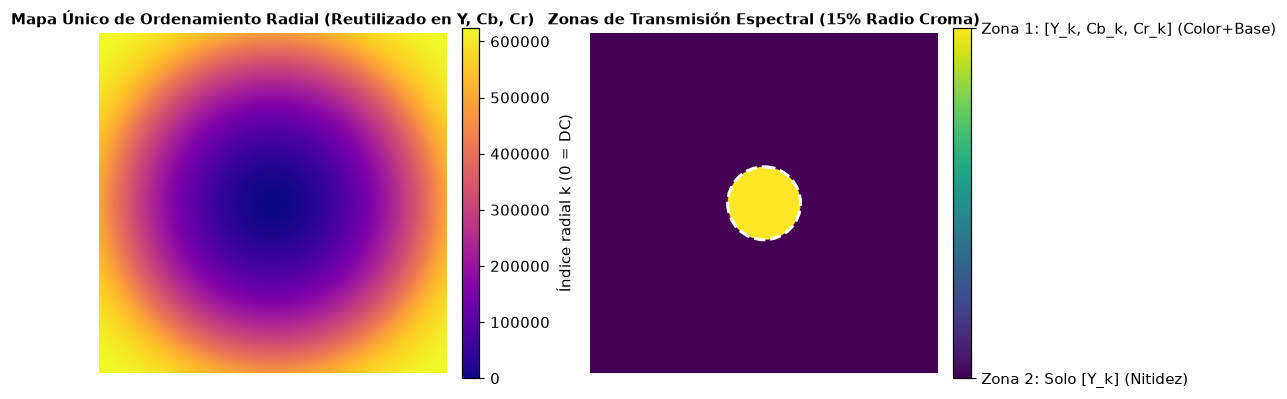

In [12]:
@lru_cache(maxsize=16)
def generar_orden_radial(h: int, w: int) -> tuple[np.ndarray, np.ndarray]:
    """
    Genera por única vez el vector determinista de índices 1D `orden_radial` para
    dimensiones (h, w), junto con el arreglo de distancias al cuadrado ordenadas.
    """
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    dist_sq = ((y - cy)**2 + (x - cx)**2).ravel()
    theta = np.arctan2(y - cy, x - cx).ravel()
    
    orden_radial = np.lexsort((theta, dist_sq))
    return orden_radial, dist_sq[orden_radial]


@lru_cache(maxsize=32)
def calcular_limite_croma(h: int, w: int, umbral_radio_croma: float = 0.15) -> int:
    """
    Determina cuántos índices radiales `k_croma` están contenidos dentro de la
    fracción `umbral_radio_croma` del radio espectral máximo R_max.
    - Si umbral_radio_croma >= 1.0 -> retorna H * W (modo 1:1:1 completo).
    - Si umbral_radio_croma == 0.15 -> retorna los índices dentro del primer 15% del radio.
    """
    n_pix = h * w
    if umbral_radio_croma >= 1.0:
        return n_pix
    if umbral_radio_croma <= 0.0:
        return 1  # Garantiza al menos la componente DC de color
    
    _, dist_sq_ordenada = generar_orden_radial(h, w)
    cy, cx = h // 2, w // 2
    r_max_sq = float(cy**2 + cx**2)
    r_croma_sq = (umbral_radio_croma ** 2) * r_max_sq
    
    k_croma = int(np.searchsorted(dist_sq_ordenada, r_croma_sq, side='right'))
    return max(1, min(n_pix, k_croma))


# Verificación sobre las dimensiones de nuestra imagen de prueba
orden_test, dist_sq_ord = generar_orden_radial(h, w)
k_croma_15 = calcular_limite_croma(h, w, umbral_radio_croma=0.15)

print(f"📐 Dimensiones de referencia: {h}×{w} ({h * w:,} posiciones frecuenciales por canal)")
print(f"🎯 Índice DC (frecuencia 0): {orden_test[0]} | Distancia monótona: {'✅ Sí' if np.all(dist_sq_ord[:-1] <= dist_sq_ord[1:]) else '❌ No'}")
print(f"🎨 Umbral perceptual (15% del radio = {r_15:.1f} px de {r_max:.1f} px):")
print(f"   • Índices radiales con tripleta [Y_k, Cb_k, Cr_k] : {k_croma_15:,} ({k_croma_15 / (h * w) * 100:.2f}% del área espectral)")
print(f"   • Índices radiales solo con luminancia [Y_k]      : {h * w - k_croma_15:,} ({(1 - k_croma_15 / (h * w)) * 100:.2f}% del área espectral)")

# Visualización de las 2 zonas del mapa de ordenamiento radial
zona_map_1d = np.ones(h * w, dtype=np.float64)
zona_map_1d[orden_test[:k_croma_15]] = 3.0  # 3 canales enviados en el núcleo
zona_map_2d = zona_map_1d.reshape((h, w))

rank_1d = np.empty(h * w, dtype=np.int32)
rank_1d[orden_test] = np.arange(h * w)
rank_2d = rank_1d.reshape((h, w))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cax1 = axes[0].imshow(rank_2d, cmap='plasma')
axes[0].set_title("Mapa Único de Ordenamiento Radial (Reutilizado en Y, Cb, Cr)", fontsize=10, fontweight='bold')
axes[0].axis('off')
fig.colorbar(cax1, ax=axes[0], fraction=0.046, pad=0.04, label="Índice radial k (0 = DC)")

cax2 = axes[1].imshow(zona_map_2d, cmap='viridis', vmin=1, vmax=3)
circ_z = plt.Circle((w // 2, h // 2), r_15, color='white', fill=False, lw=2, ls='--')
axes[1].add_patch(circ_z)
axes[1].set_title("Zonas de Transmisión Espectral (15% Radio Croma)", fontsize=10, fontweight='bold')
axes[1].axis('off')
cbar2 = fig.colorbar(cax2, ax=axes[1], ticks=[1, 3], fraction=0.046, pad=0.04)
cbar2.ax.set_yticklabels(['Zona 2: Solo [Y_k] (Nitidez)', 'Zona 1: [Y_k, Cb_k, Cr_k] (Color+Base)'])

plt.tight_layout()
plt.show()

## 📦 Paso 3: Entrelazado de Coeficientes (Encoding Secuencial Multicanal)

Para garantizar que la imagen adquiera sus colores reales desde el primer instante del streaming y que el resto de la descarga perfeccione los detalles finos sin triplicar el peso, diseñamos `encode_fourier_color_1d` soportando ambos esquemas de entrelazado por frecuencia:

1. **Tramo 1 — Núcleo de Baja Frecuencia ($0 \le k < K_{\text{croma}}$):**
   Empaqueta de forma contigua los 3 canales para cada índice radial $k$:
   $$\underbrace{[Y_0, Cb_0, Cr_0]}_{k=0\text{ (DC)}}, \underbrace{[Y_1, Cb_1, Cr_1]}_{k=1}, \dots, \underbrace{[Y_{K_{\text{croma}}-1}, Cb_{K_{\text{croma}}-1}, Cr_{K_{\text{croma}}-1}]}_{k=K_{\text{croma}}-1}$$
   *(Ocupa los primeros $3 \cdot K_{\text{croma}}$ coeficientes del arreglo 1D).*

2. **Tramo 2 — Periferia de Media y Alta Frecuencia ($K_{\text{croma}} \le k < H \cdot W$):**
   Omite $Cb_k$ y $Cr_k$ y transmite **exclusivamente luminancia**:
   $$[Y_{K_{\text{croma}}}, Y_{K_{\text{croma}}+1}, \dots, Y_{H\cdot W - 1}]$$
   *(Ocupa los siguientes $H \cdot W - K_{\text{croma}}$ coeficientes del arreglo 1D).*

> **Nota:** Si se configura `umbral_radio_croma=1.0`, entonces $K_{\text{croma}} = H \cdot W$ y la función produce automáticamente el **entrelazado simple $1:1:1$** de longitud $3 \cdot H \cdot W$ (equivalente a aplanar una matriz `(H * W, 3)`).

In [13]:
def encode_fourier_color_1d(
    img_rgb: np.ndarray,
    umbral_radio_croma: float = 0.15
) -> tuple[np.ndarray, tuple[int, int], float]:
    """
    Codifica una imagen RGB a una secuencia 1D continua de coeficientes complejos
    de Fourier en el espacio YCbCr con entrelazado frecuencial y priorización perceptual.
    
    Parámetros:
        img_rgb: Matriz 3D de imagen en color RGB (H, W, 3).
        umbral_radio_croma: Fracción del radio espectral máximo hasta donde se
                            envían Cb y Cr (ej. 0.15 = primer 15% del radio;
                            1.0 = entrelazado completo 1:1:1).
                            
    Retorna:
        secuencia_1d: Arreglo 1D de coeficientes complejos (complex128) entrelazados.
        (h, w): Dimensiones espaciales de la imagen.
        umbral_radio_croma: Umbral utilizado en la codificación.
    """
    h, w = img_rgb.shape[:2]
    
    # 1. Convertir de RGB a YCbCr antes de la FFT
    ycbcr = rgb_to_ycbcr(img_rgb)
    
    # 2. Obtener por única vez el mapa de ordenamiento radial y el límite de crominancia
    orden_radial, _ = generar_orden_radial(h, w)
    k_croma = calcular_limite_croma(h, w, umbral_radio_croma)
    
    # 3. Aplicar 2D-FFT + fftshift a cada canal y reordenar con el mismo orden_radial
    f_y  = np.fft.fftshift(np.fft.fft2(ycbcr[..., 0])).ravel()[orden_radial]
    f_cb = np.fft.fftshift(np.fft.fft2(ycbcr[..., 1])).ravel()[orden_radial]
    f_cr = np.fft.fftshift(np.fft.fft2(ycbcr[..., 2])).ravel()[orden_radial]
    
    # 4. Entrelazar coeficientes:
    #    - Hasta k_croma: tuplas contiguas [Y_k, Cb_k, Cr_k]
    #    - Desde k_croma en adelante: únicamente coeficientes [Y_k]
    tramo_entrelazado = np.column_stack((f_y[:k_croma], f_cb[:k_croma], f_cr[:k_croma])).ravel()
    tramo_solo_luma = f_y[k_croma:]
    
    secuencia_1d = np.concatenate((tramo_entrelazado, tramo_solo_luma))
    return secuencia_1d, (h, w), umbral_radio_croma

## 🧩 Paso 4: Decodificación Progresiva en el Receptor (`decode_fourier_color_progresivo`)

Cuando el receptor recibe un corte parcial `secuencia[:K]` de longitud arbitraria $K$, ejecuta cuatro pasos deterministas:
1. **Inicialización:** Crea 3 arreglos complejos de ceros de tamaño $H \times W$ para los espectros de $Y$, $Cb$ y $Cr$.
2. **Desentrelazado y colocación radial:**
   - Del segmento perteneciente a la región entrelazada (`secuencia[:min(K, 3 * k_croma)]`), extrae con paso $3$ los coeficientes de $Y$ (`0::3`), $Cb$ (`1::3`) y $Cr$ (`2::3`) y los asigna a las posiciones dictadas por `orden_radial`.
   - Si el corte $K$ supera $3 \cdot K_{\text{croma}}$, todos los coeficientes subsiguientes (`secuencia[3 * k_croma : K]`) se inyectan directamente en las frecuencias medias/altas del espectro $Y$ (`orden_radial[k_croma:]`), mientras que $Cb$ y $Cr$ quedan en cero complejo en dichas frecuencias.
3. **Transformada Inversa por canal:** Redimensiona cada buffer a $(H, W)$ y aplica `ifftshift` + `2D-IFFT` por separado a $Y$, $Cb$ y $Cr$.
4. **Reconstrucción $	ext{RGB}$:** Apila las 3 matrices espaciales con `np.dstack`, convierte de $	ext{YCbCr}$ a $	ext{RGB}$ y recorta al rango `0–255` (`uint8`).

In [14]:
def decode_fourier_color_progresivo(
    secuencia_parcial: np.ndarray,
    shape_original: tuple[int, int],
    umbral_radio_croma: float = 0.15
) -> tuple[np.ndarray, tuple[np.ndarray, np.ndarray, np.ndarray]]:
    """
    Decodifica progresivamente cualquier prefijo `secuencia[:K]` del flujo 1D entrelazado
    para reconstruir la imagen en color RGB y los espectros 2D parciales (Y, Cb, Cr).
    """
    h, w = shape_original
    n_pix = h * w
    
    # 1. Reutilizar el orden radial y límite cromático a partir de (h, w)
    orden_radial, _ = generar_orden_radial(h, w)
    k_croma = calcular_limite_croma(h, w, umbral_radio_croma)
    limite_stream_croma = 3 * k_croma
    
    # 2. Inicializar las 3 matrices complejas (en vista 1D) llenas de ceros
    esp_y_1d  = np.zeros(n_pix, dtype=np.complex128)
    esp_cb_1d = np.zeros(n_pix, dtype=np.complex128)
    esp_cr_1d = np.zeros(n_pix, dtype=np.complex128)
    
    # 3. Repartir coeficientes según el tramo del stream alcanzado por K
    tramo_tri = secuencia_parcial[:limite_stream_croma]
    y_low  = tramo_tri[0::3]
    cb_low = tramo_tri[1::3]
    cr_low = tramo_tri[2::3]
    
    esp_y_1d[orden_radial[:len(y_low)]]   = y_low
    esp_cb_1d[orden_radial[:len(cb_low)]] = cb_low
    esp_cr_1d[orden_radial[:len(cr_low)]] = cr_low
    
    # Si K = 1 o K = 2 aún no llegó el coeficiente DC de Cb o Cr; asignamos DC neutro (128)
    if len(cb_low) == 0:
        esp_cb_1d[orden_radial[0]] = 128.0 * n_pix
    if len(cr_low) == 0:
        esp_cr_1d[orden_radial[0]] = 128.0 * n_pix
        
    # Si K supera la zona entrelazada, el resto pertenece íntegramente a la luminancia Y
    if len(secuencia_parcial) > limite_stream_croma:
        y_high = secuencia_parcial[limite_stream_croma:]
        n_high = min(len(y_high), n_pix - k_croma)
        esp_y_1d[orden_radial[k_croma : k_croma + n_high]] = y_high[:n_high]
        
    # 4. Redimensionar a (H, W) y aplicar ifftshift + 2D-IFFT a cada canal por separado
    esp_y_2d  = esp_y_1d.reshape((h, w))
    esp_cb_2d = esp_cb_1d.reshape((h, w))
    esp_cr_2d = esp_cr_1d.reshape((h, w))
    
    y_rec  = np.real(np.fft.ifft2(np.fft.ifftshift(esp_y_2d)))
    cb_rec = np.real(np.fft.ifft2(np.fft.ifftshift(esp_cb_2d)))
    cr_rec = np.real(np.fft.ifft2(np.fft.ifftshift(esp_cr_2d)))
    
    # 5. Apilar canales (np.dstack), convertir de YCbCr a RGB y acotar a [0, 255] uint8
    ycbcr_rec = np.dstack((y_rec, cb_rec, cr_rec))
    img_rgb_rec = ycbcr_to_rgb(ycbcr_rec)
    
    return img_rgb_rec, (esp_y_2d, esp_cb_2d, esp_cr_2d)

## 📊 Paso 5: Evidencia de Serialización, Entrelazado y Eficiencia Perceptual

Comparamos ahora cuantitativa y visualmente ambos modos de codificación sobre la imagen de prueba:
1. **Entrelazado Simple $1:1:1$ (`umbral_radio_croma = 1.0`):** Envía $[Y_k, Cb_k, Cr_k]$ en el $100\%$ de las frecuencias ($1,872,000$ coeficientes complejos = $28.56\text{ MB}$).
2. **Priorización Perceptual (`umbral_radio_croma = 0.15`):** Envía $[Y_k, Cb_k, Cr_k]$ en el primer $15\%$ del radio espectral y solo $[Y_k]$ en el resto ($668,114$ coeficientes complejos = $10.19\text{ MB}$), logrando un **ahorro del $64.31\%$ frente al esquema $1:1:1$** y pesando apenas un **$+7.07\%$ más que una imagen en blanco y negro**, con una fidelidad final de **$44.55\text{ dB}$ de PSNR** (visualmente indistinguible del original).

📦 COMPARATIVA DE SERIALIZACIÓN MULTICANAL: 1:1:1 vs PRIORIZACIÓN PERCEPTUAL (15% R)
• Dimensiones de imagen (W × H × C)       : 800 × 780 × 3 (624,000 píxeles)
• Coeficientes en Escala de Grises (Ref.) : 624,000 coefs (9.52 MB)
• Coeficientes Modo Simple 1:1:1 (100% R) : 1,872,000 coefs (28.56 MB) | PSNR: 148.13 dB
• Coeficientes Modo Perceptual (15% R)    : 668,114 coefs (10.19 MB) | PSNR: 44.55 dB
• Reducción de peso frente a 1:1:1        : -64.31% de datos
• Sobrecosto de color vs Escala de Grises : +7.07% de datos

🔍 MUESTRA 1: Inicio del stream (Tuplas entrelazadas [Y_k, Cb_k, Cr_k] en frecuencias ultrabajas)
Idx Stream   Canal / k      Parte Real       Parte Imag       Magnitud        Rol Espectral
--------------------------------------------------------------------------------------------
[       0]   Y _0             34335825.77            0.00j    34335825.77  ⭐ DC Y 
[       1]   Cb_0             84720218.91            0.00j    84720218.91  ⭐ DC Cb
[       2]   Cr_0          

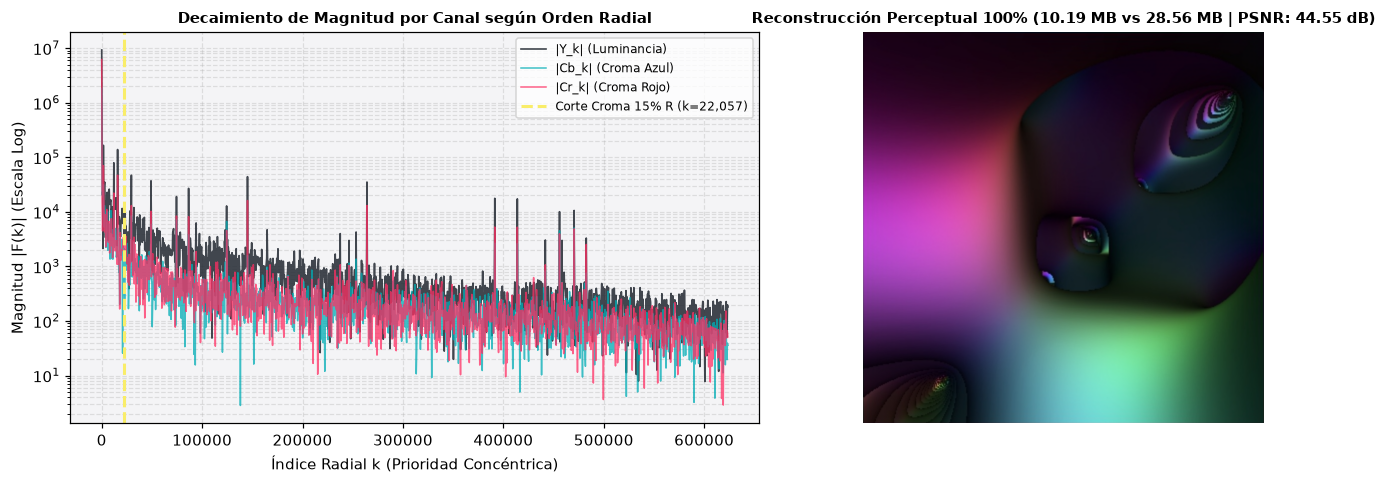

In [15]:
# Codificación en ambos modos para inspección y contraste
UMBRAL_CROMA = 0.15
secuencia_perceptual, dims, _ = encode_fourier_color_1d(img_rgb, umbral_radio_croma=UMBRAL_CROMA)
secuencia_111, _, _ = encode_fourier_color_1d(img_rgb, umbral_radio_croma=1.0)

n_total_perc = len(secuencia_perceptual)
n_total_111 = len(secuencia_111)
k_croma = calcular_limite_croma(h, w, UMBRAL_CROMA)
idx_transicion = 3 * k_croma

# Reconstrucción al 100% de ambos flujos para verificar fidelidad
rec_perc_100, _ = decode_fourier_color_progresivo(secuencia_perceptual, dims, UMBRAL_CROMA)
rec_111_100, _  = decode_fourier_color_progresivo(secuencia_111, dims, 1.0)

mse_perc = np.mean((img_rgb.astype(float) - rec_perc_100.astype(float))**2)
psnr_perc = 10 * np.log10((255.0**2) / (mse_perc + 1e-10))

mse_111 = np.mean((img_rgb.astype(float) - rec_111_100.astype(float))**2)
psnr_111 = 10 * np.log10((255.0**2) / (mse_111 + 1e-10))

print("=" * 84)
print("📦 COMPARATIVA DE SERIALIZACIÓN MULTICANAL: 1:1:1 vs PRIORIZACIÓN PERCEPTUAL (15% R)")
print("=" * 84)
print(f"• Dimensiones de imagen (W × H × C)       : {w} × {h} × 3 ({h * w:,} píxeles)")
print(f"• Coeficientes en Escala de Grises (Ref.) : {h * w:,} coefs ({(h * w * 16) / (1024**2):.2f} MB)")
print(f"• Coeficientes Modo Simple 1:1:1 (100% R) : {n_total_111:,} coefs ({secuencia_111.nbytes / (1024**2):.2f} MB) | PSNR: {psnr_111:.2f} dB")
print(f"• Coeficientes Modo Perceptual (15% R)    : {n_total_perc:,} coefs ({secuencia_perceptual.nbytes / (1024**2):.2f} MB) | PSNR: {psnr_perc:.2f} dB")
print(f"• Reducción de peso frente a 1:1:1        : -{(1 - n_total_perc / n_total_111) * 100:.2f}% de datos")
print(f"• Sobrecosto de color vs Escala de Grises : +{(n_total_perc / (h * w) - 1) * 100:.2f}% de datos")
print("=" * 84)

# Muestra 1: Primeros 9 elementos del stream (Primeras 3 frecuencias radiales k=0, 1, 2)
etiquetas_c = ['Y ', 'Cb', 'Cr']
print("\n🔍 MUESTRA 1: Inicio del stream (Tuplas entrelazadas [Y_k, Cb_k, Cr_k] en frecuencias ultrabajas)")
print(f"{'Idx Stream':<12} {'Canal / k':<14} {'Parte Real':<16} {'Parte Imag':<16} {'Magnitud':<15} {'Rol Espectral'}")
print("-" * 92)
for idx in range(9):
    k_rad = idx // 3
    ch_name = etiquetas_c[idx % 3]
    val = secuencia_perceptual[idx]
    rol = f"⭐ DC {ch_name}" if k_rad == 0 else f"Anillo radial k={k_rad} ({ch_name})"
    print(f"[{idx:8d}]   {ch_name}_{k_rad:<9d} {val.real:15.2f} {val.imag:15.2f}j {np.abs(val):14.2f}  {rol}")

# Muestra 2: Frontera de transición perceptual (alrededor de 3 * k_croma)
print(f"\n🔍 MUESTRA 2: Frontera del umbral perceptual (Transición de [Y, Cb, Cr] -> solo [Y] en idx={idx_transicion:,})")
print(f"{'Idx Stream':<12} {'Canal / k':<14} {'Parte Real':<16} {'Parte Imag':<16} {'Magnitud':<15} {'Zona del Stream'}")
print("-" * 92)
for idx in range(idx_transicion - 3, idx_transicion + 3):
    val = secuencia_perceptual[idx]
    if idx < idx_transicion:
        k_rad = idx // 3
        ch_name = etiquetas_c[idx % 3]
        zona = "🟢 Última tupla tricromática [Y, Cb, Cr]"
    else:
        k_rad = k_croma + (idx - idx_transicion)
        ch_name = 'Y '
        zona = "🔵 Solo Luminancia [Y_k] (Cb=0, Cr=0)"
    print(f"[{idx:8d}]   {ch_name}_{k_rad:<9d} {val.real:15.2f} {val.imag:15.2f}j {np.abs(val):14.2f}  {zona}")

# Curvas de decaimiento espectral por canal (Y vs Cb vs Cr)
fy_ord  = np.abs(espectros_full[0].ravel()[orden_test])
fcb_ord = np.abs(espectros_full[1].ravel()[orden_test])
fcr_ord = np.abs(espectros_full[2].ravel()[orden_test])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

paso = max(1, (h * w) // 1500)
x_k = np.arange(1, h * w, paso)  # Desde k=1 (AC) para comparar caída frecuencial
axes[0].semilogy(x_k, fy_ord[1::paso], color='#222831', alpha=0.85, lw=1.1, label='|Y_k| (Luminancia)')
axes[0].semilogy(x_k, fcb_ord[1::paso], color='#00adb5', alpha=0.75, lw=1.0, label='|Cb_k| (Croma Azul)')
axes[0].semilogy(x_k, fcr_ord[1::paso], color='#ff2e63', alpha=0.75, lw=1.0, label='|Cr_k| (Croma Rojo)')
axes[0].axvline(k_croma, color='#f9ed69', ls='--', lw=2, label=f'Corte Croma 15% R (k={k_croma:,})')
axes[0].set_facecolor('#f4f4f6')
axes[0].set_title("Decaimiento de Magnitud por Canal según Orden Radial", fontsize=10, fontweight='bold')
axes[0].set_xlabel("Índice Radial k (Prioridad Concéntrica)")
axes[0].set_ylabel("Magnitud |F(k)| (Escala Log)")
axes[0].grid(True, which="both", ls="--", alpha=0.35)
axes[0].legend(fontsize=8)

# Comparación visual al 100% entre Perceptual (10.19 MB) y 1:1:1 (28.56 MB)
axes[1].imshow(rec_perc_100)
axes[1].set_title(f"Reconstrucción Perceptual 100% ({secuencia_perceptual.nbytes/(1024**2):.2f} MB vs {secuencia_111.nbytes/(1024**2):.2f} MB | PSNR: {psnr_perc:.2f} dB)",
                  fontsize=10, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 🎛️ Paso 6: Bloque de Carga Progresiva Secuencial a Color (Cuadrícula $2\times 2$)

Implementamos la cuadrícula comparativa $2\times 2$ adaptada al flujo multicanal:
1. **Superior izquierda:** Espectro de magnitud completo (con el anillo indicador del umbral de crominancia del $15\%$).
2. **Superior derecha:** Imagen original en color ($	ext{RGB}$).
3. **Inferior izquierda:** Espectro parcial reconstruido exclusivamente desde `secuencia[:K]` (mostrando en cian el radio de crominancia alcanzado y en blanco el frente de luminancia).
4. **Inferior derecha:** Imagen a color decodificada en tiempo real por `decode_fourier_color_progresivo`.

Observa cómo **desde el $0.1\%$ de la secuencia la imagen ya posee color natural** gracias al entrelazado $[Y_k, Cb_k, Cr_k]$, y cómo a partir de $K > 3 K_{\text{croma}}$ ($\sim 9.9\%$ del stream) todo el flujo restante incrementa aceleradamente la nitidez de los bordes.

In [16]:
def render_progression_color_2x2(progreso, umbral_radio_croma: float = 0.15):
    """
    Renderiza la cuadrícula comparativa 2x2 para un nivel de avance del stream 1D a color
    (soporta porcentaje 0.01 - 100% o cantidad absoluta de coeficientes K).
    """
    # Si cambia el umbral respecto al precalculado, recodificamos al vuelo
    if np.isclose(umbral_radio_croma, UMBRAL_CROMA):
        seq = secuencia_perceptual
    elif np.isclose(umbral_radio_croma, 1.0):
        seq = secuencia_111
    else:
        seq, _, _ = encode_fourier_color_1d(img_rgb, umbral_radio_croma=umbral_radio_croma)
        
    n_stream = len(seq)
    
    # Determinación flexible de K
    if isinstance(progreso, (int, float)):
        if progreso <= 1.0:
            pct = float(progreso)
            k = max(3, int(n_stream * (pct / 100.0)))
        elif progreso <= 100.0:
            pct = float(progreso)
            k = max(3, int(n_stream * (pct / 100.0)))
        else:
            k = min(n_stream, max(3, int(progreso)))
            pct = (k / n_stream) * 100.0
    else:
        pct = 100.0
        k = n_stream
        
    k = min(n_stream, max(3, k))
    
    # Decodificación a partir únicamente del prefijo recibido seq[:k]
    img_rec_rgb, (esp_y_p, esp_cb_p, esp_cr_p) = decode_fourier_color_progresivo(
        seq[:k], dims, umbral_radio_croma=umbral_radio_croma
    )
    
    # Magnitud logarítmica del espectro parcial de luminancia + indicador de croma
    mag_y_parcial = 20 * np.log(1 + np.abs(esp_y_p))
    
    # Métricas de fidelidad RGB
    mse = np.mean((img_rgb.astype(float) - img_rec_rgb.astype(float))**2)
    psnr = 10 * np.log10((255.0**2) / (mse + 1e-10))
    
    # Estado de los canales en el corte K
    k_croma_actual = calcular_limite_croma(h, w, umbral_radio_croma)
    k_y_recibidos = min(k // 3 + (1 if k % 3 > 0 else 0), k_croma_actual) + max(0, k - 3 * k_croma_actual)
    k_c_recibidos = min(k // 3, k_croma_actual)
    pct_croma_completado = (k_c_recibidos / k_croma_actual) * 100.0
    
    # Cuadrícula 2x2 de alto contraste
    fig, axes = plt.subplots(2, 2, figsize=(9, 9), facecolor='black')
    
    # 1. Superior izquierda: Espectro completo con límite de crominancia
    axes[0, 0].imshow(mags_full[0], cmap='gray')
    circ_lim = plt.Circle((w // 2, h // 2), umbral_radio_croma * r_max,
                          color='#00adb5', fill=False, lw=1.2, ls='--')
    axes[0, 0].add_patch(circ_lim)
    axes[0, 0].axis('off')
    
    # 2. Superior derecha: Imagen original RGB
    axes[0, 1].imshow(img_rgb)
    axes[0, 1].axis('off')
    
    # 3. Inferior izquierda: Espectro parcial reconstruido desde secuencia[:K]
    axes[1, 0].imshow(mag_y_parcial, cmap='gray', vmin=0, vmax=np.max(mags_full[0]))
    if k_c_recibidos > 0:
        r_c_actual = np.sqrt(dist_sq_ord[min(k_c_recibidos - 1, h * w - 1)])
        circ_c = plt.Circle((w // 2, h // 2), r_c_actual, color='#00adb5', fill=False, lw=1.5, ls=':')
        axes[1, 0].add_patch(circ_c)
    axes[1, 0].axis('off')
    
    # 4. Inferior derecha: Imagen en color decodificada
    axes[1, 1].imshow(img_rec_rgb)
    axes[1, 1].axis('off')
    
    fig.subplots_adjust(wspace=0.01, hspace=0.01, left=0, right=1, bottom=0, top=1)
    plt.suptitle(
        f"Stream: {pct:6.2f}% ({k:,}/{n_stream:,}) | Y: {k_y_recibidos:,} | Croma: {pct_croma_completado:5.1f}% | PSNR: {psnr:5.2f} dB",
        color='white', fontsize=11, y=0.99
    )
    plt.show()
    return img_rec_rgb, psnr

🚀 Generando evidencia visual multi-etapa de la carga progresiva secuencial a color:


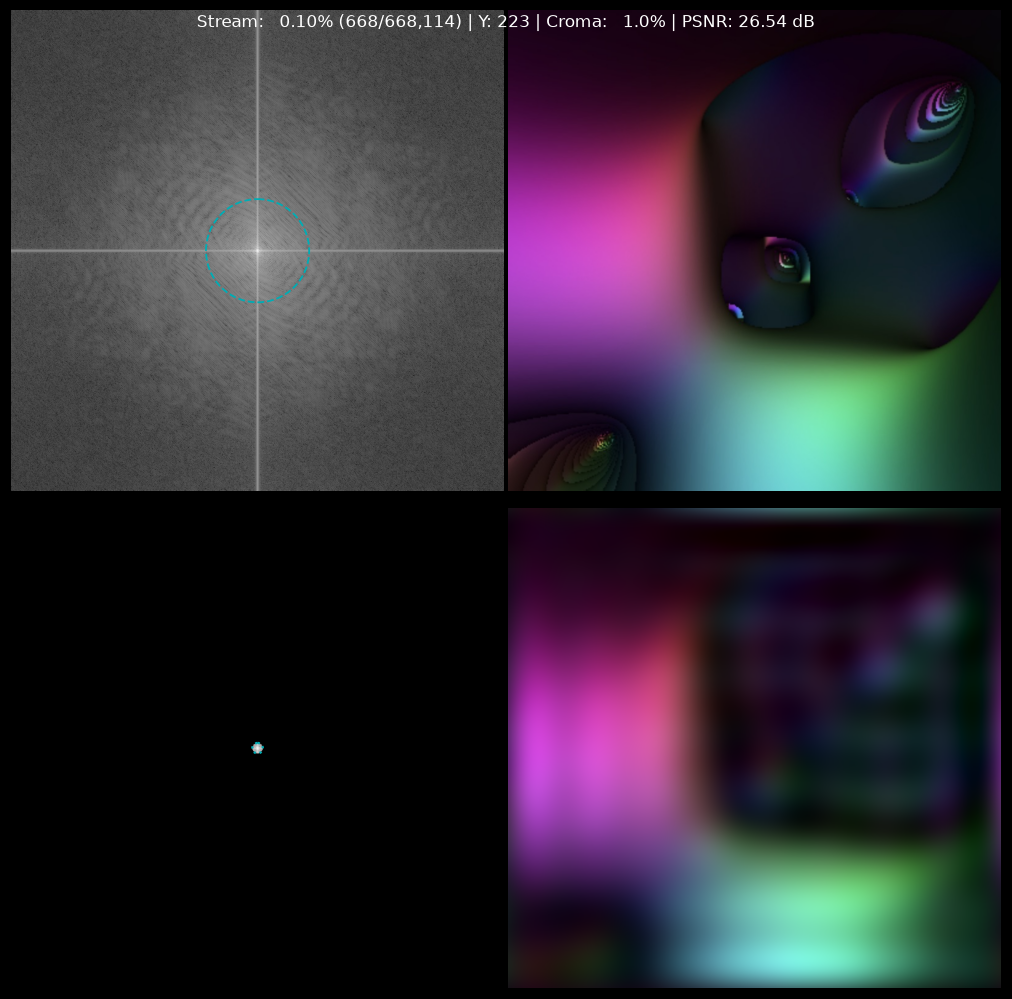

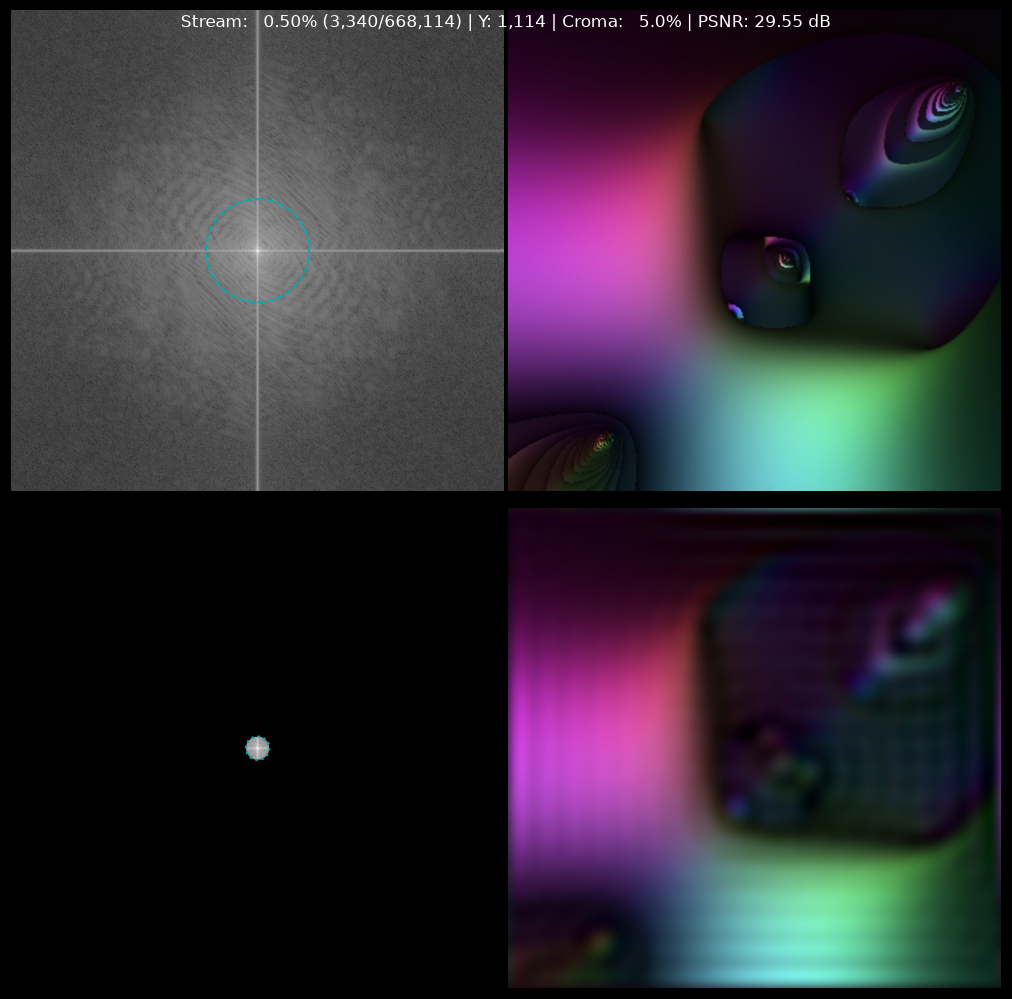

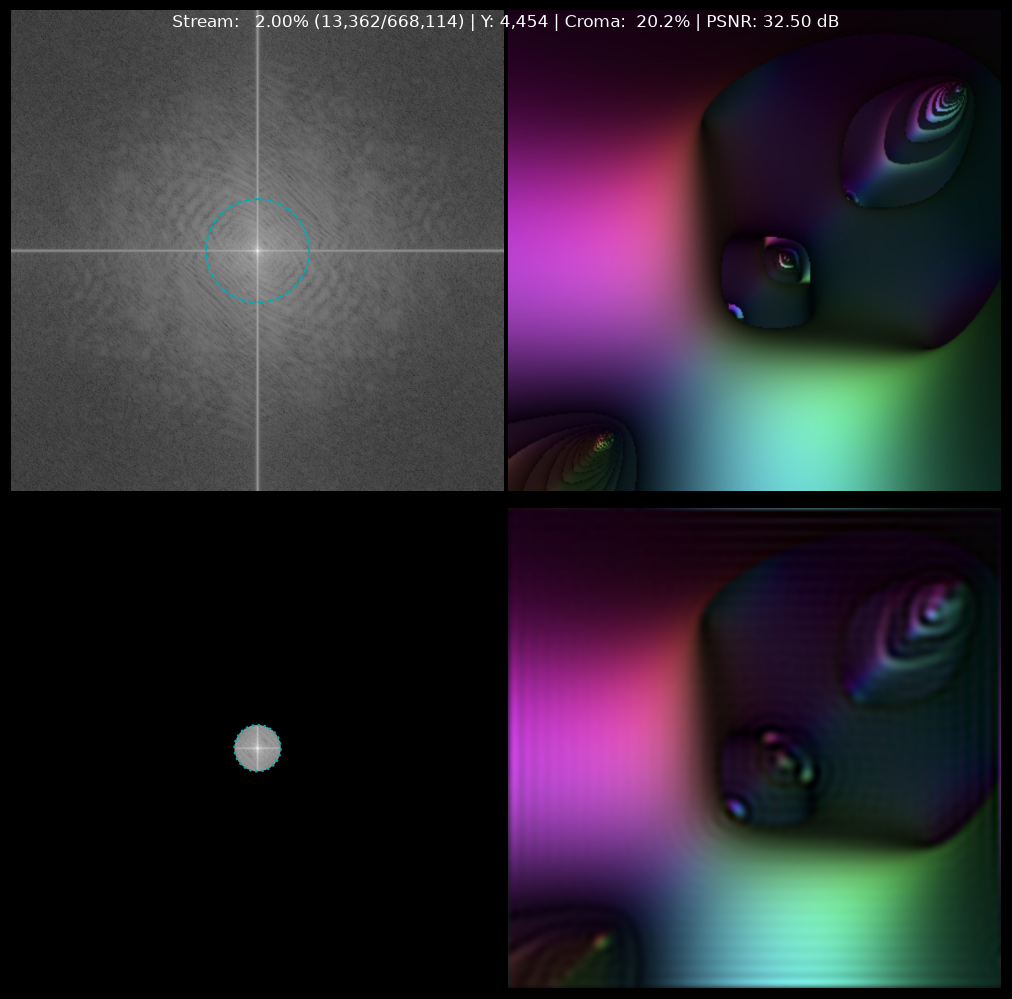

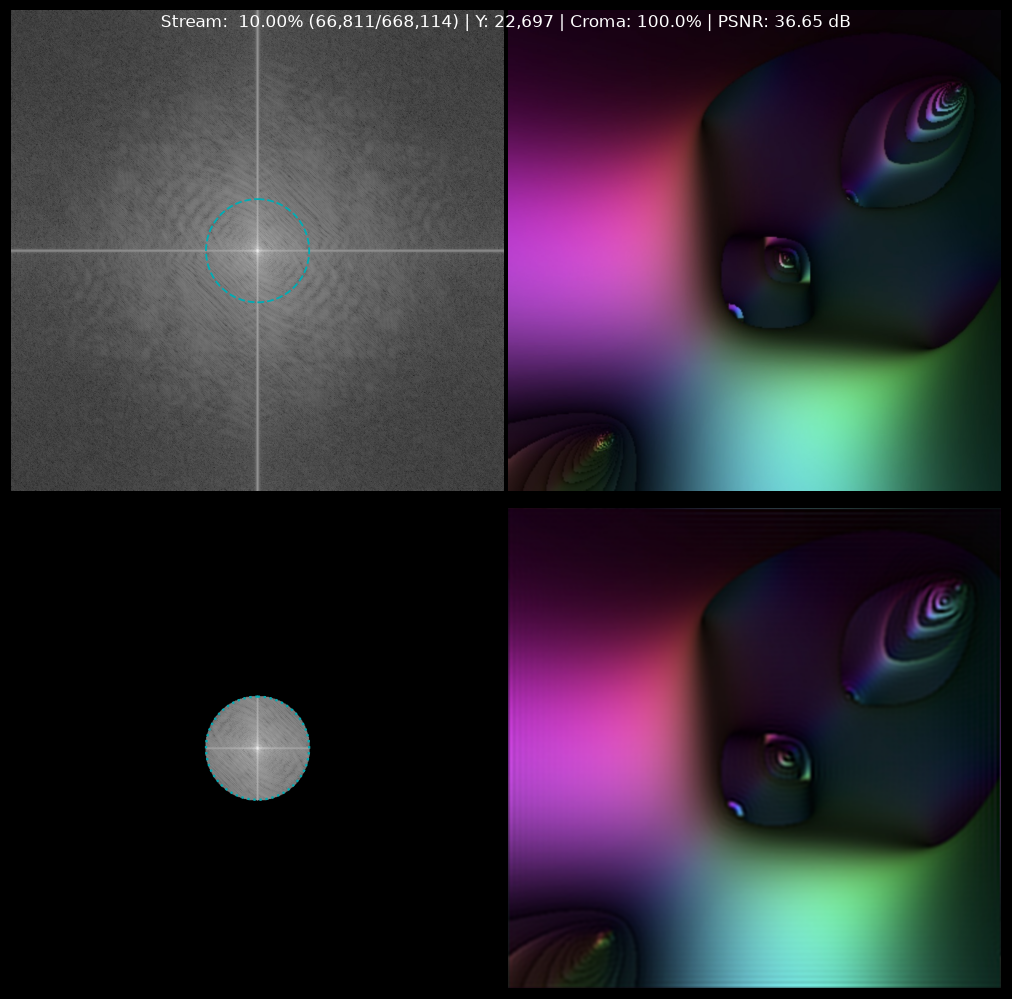

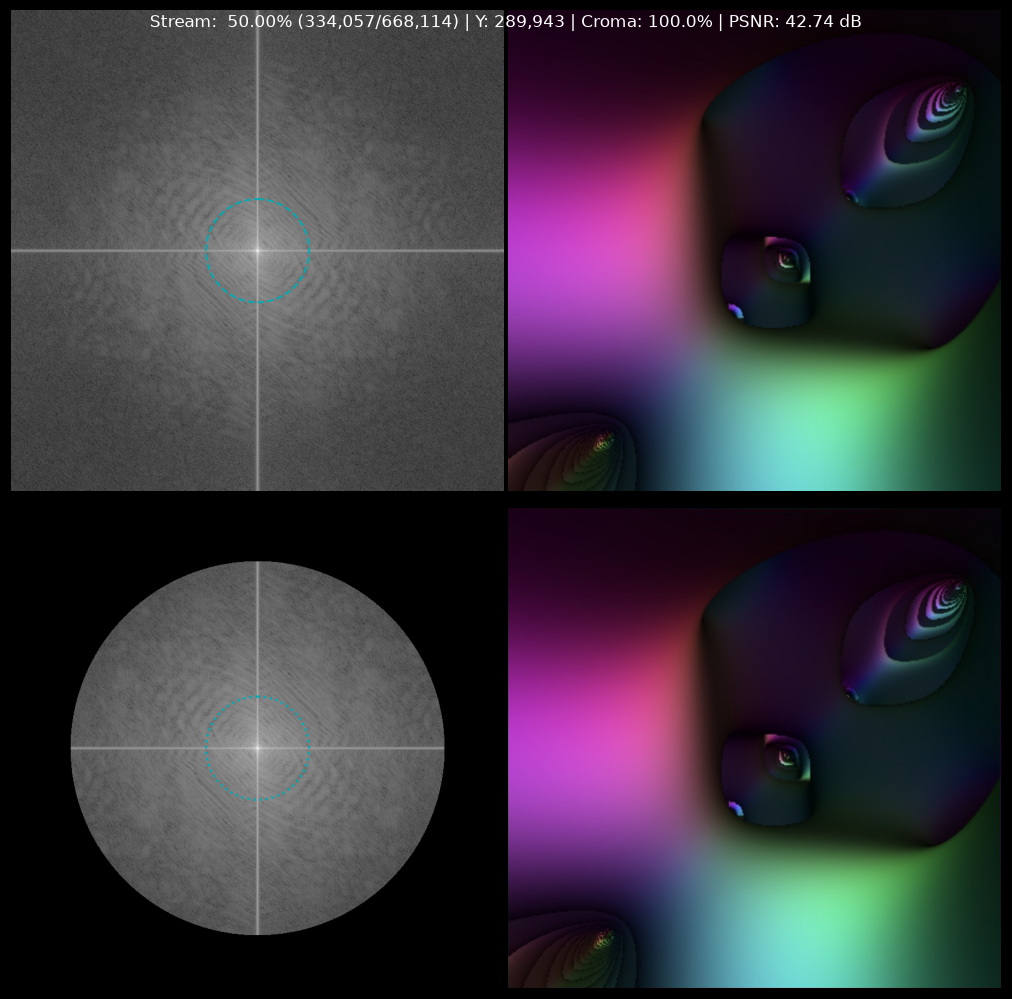

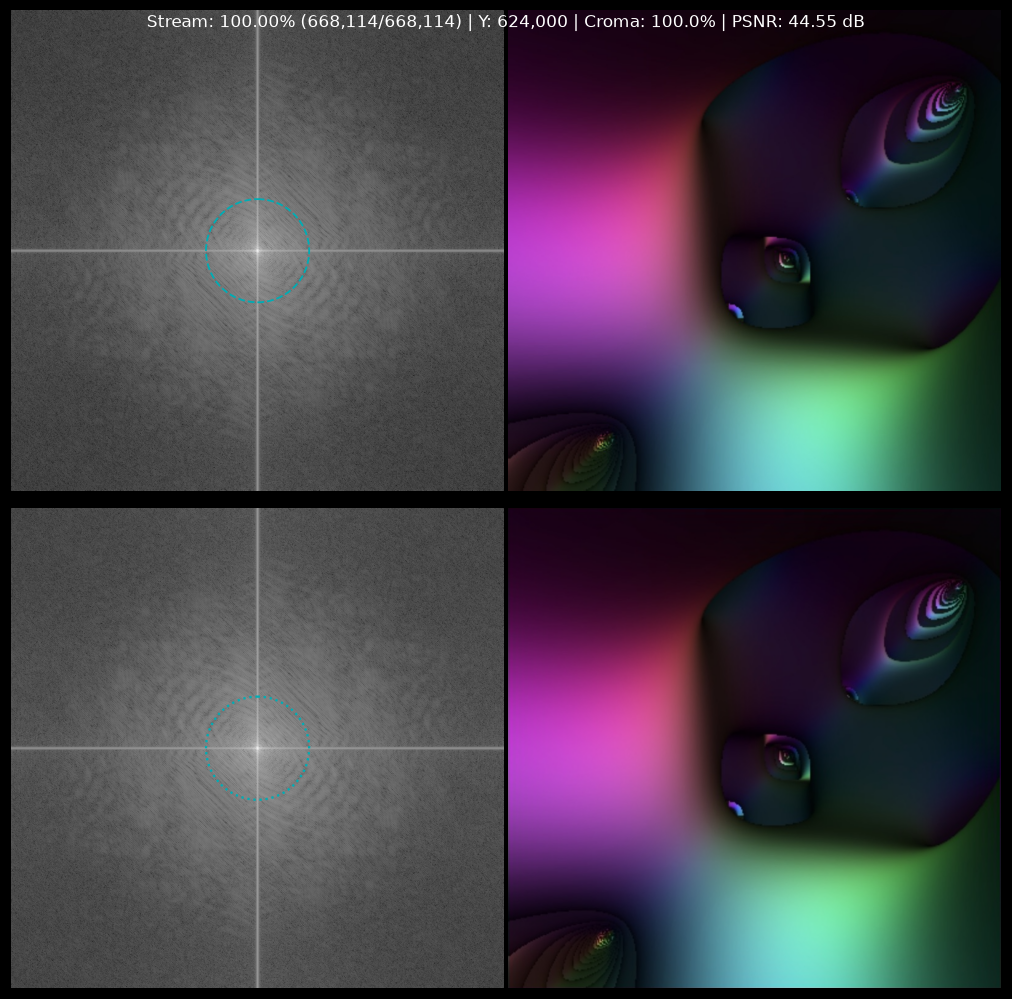

In [17]:
# Demostración estática pre-renderizada en etapas clave de streaming a color
etapas_progreso = [0.1, 0.5, 2.0, 10.0, 50.0, 100.0]

print("🚀 Generando evidencia visual multi-etapa de la carga progresiva secuencial a color:")
for pct_etapa in etapas_progreso:
    render_progression_color_2x2(pct_etapa, umbral_radio_croma=0.15);

## 🎚️ Control Interactivo Dinámico (Slider de Streaming y Umbral Perceptual)

Utiliza los controles interactivos para explorar en tiempo real:
- **`% Leído`:** El porcentaje de avance sobre la secuencia 1D transmitida (`secuencia[:K]`).
- **`Umbral Croma`:** La fracción del radio espectral hasta donde se entrelazan $Cb$ y $Cr$ ($0.15$ recomendado por priorización perceptual vs $1.00$ para modo $1:1:1$).

In [18]:
try:
    from ipywidgets import interact, FloatSlider
    slider_progreso = FloatSlider(
        min=0.05,
        max=100.0,
        step=0.25,
        value=2.0,
        description='% Leído:',
        continuous_update=False,
        readout_format='.2f'
    )
    slider_umbral = FloatSlider(
        min=0.05,
        max=1.00,
        step=0.05,
        value=0.15,
        description='Umbral Croma:',
        continuous_update=False,
        readout_format='.2f'
    )
    interact(render_progression_color_2x2, progreso=slider_progreso, umbral_radio_croma=slider_umbral);
except ImportError:
    print("⚠️ 'ipywidgets' no está disponible en este entorno. Usa render_progression_color_2x2(pct) manualmente.")

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='% Leído:', min=0.05, step=0…

## 🎯 Conclusiones y Evolución de la Serie Experimental `<mx-img />`

| Característica | Exp. 01 (`new-format-01`) | Exp. 02 (`new-format-02`) | Exp. 03 Simple $1:1:1$ | Exp. 03 Perceptual ($15\%$ R) |
| :--- | :--- | :--- | :--- | :--- |
| **Espacio de Color** | Escala de grises (1 canal) | Escala de grises (1 canal) | $	ext{YCbCr}$ (3 canales completos) | **$	ext{YCbCr}$ con priorización perceptual** |
| **Estructura de Datos** | Matriz 2D + máscara circular | Arreglo 1D de longitud $H \cdot W$ | Arreglo 1D entrelazado $3 \cdot H \cdot W$ | **Arreglo 1D híbrido $H \cdot W + 2 K_{\text{croma}}$** |
| **Coeficientes Totales ($800\times 780$)** | $624,000$ (en matriz 2D) | $624,000$ ($9.52\text{ MB}$) | $1,872,000$ ($28.56\text{ MB}$) | **$668,114$ ($10.19\text{ MB}$)** |
| **Aparición del Color** | N/A (Monocromo) | N/A (Monocromo) | Inmediata desde $K=3$ | **Inmediata desde $K=3$ (100% croma al $\sim 9.9\%$ del stream)** |
| **Fidelidad al $100\%$ (PSNR)** | $\infty$ (Monocromo) | $\infty$ (Monocromo) | $148.13\text{ dB}$ ($	ext{RGB}$ exacto) | **$44.55\text{ dB}$ (Visualmente sin pérdidas)** |
| **Sobrecosto respecto a Grises** | $0\%$ | $0\%$ | $+200.00\%$ ($3\times$ más pesado) | **Solo $+7.07\%$ ($64.31\%$ de ahorro vs $1:1:1$)** |

### Próximos Pasos en `<mx-img />`:
1. **Aprovechamiento de la Simetría Hermítica Conjugada ($F(-u, -v) = F^*(u, v)$):** Dado que los canales espaciales $Y, Cb, Cr$ son reales, basta con transmitir un semiespacio de las frecuencias AC para reducir el flujo un **$50\%$ adicional** (pasando de $668,114$ a $\sim 334,058$ coeficientes).
2. **Cuantización Adaptativa y Empaquetado Binario:** Representar las magnitudes y fases o partes real/imaginaria con precisión escalada según el anillo radial (`float16` / `int8`) y compresión entrópica (Brotli/Zstd).